# Modelagem: Filtragem Colaborativa com SVD (Funk SVD)

---

## Contexto

A Plataforma Spotlight ainda não possui um mecanismo estruturado de recomendação de espetáculos. Na prática, isso limita a descoberta de novas experiências: o usuário visualiza um espetáculo específico, mas não recebe sugestões personalizadas com base em seu perfil comportamental ou em padrões de avaliação de usuários semelhantes.

Este notebook implementa a etapa de modelagem utilizando o dataset balanceado preparado na Sprint 1. O objetivo é construir um modelo de **filtragem colaborativa baseada em fatoração matricial (Funk SVD)** capaz de prever a nota que um usuário daria a um espetáculo e gerar listas de recomendações personalizadas.

Ao final do pipeline, são gerados os artefatos principais abaixo:

| Arquivo | Finalidade |
|---|---|
| `svd_model.pkl` | Modelo SVD final treinado, pronto para inferência |
| `gridsearch_results.csv` | Tabela completa dos hiperparâmetros testados via Grid Search |
| `comparativo_modelos.csv` | Resultados comparativos KNN vs SVD |

---

## Estrutura do Notebook

| Seção | Descrição |
|---|---|
| 1. Configuração do Ambiente | Instalação e imports |
| 2. Conexão com a Base da Sprint 1 | Análise crítica do dataset herdado |
| 3. Carregamento dos Dados | Leitura do dataset balanceado |
| 4. Análise Exploratória | Visão geral do dataset de modelagem |
| 5. Construção da Matriz Usuário-Item | Pivot table e esparsidade |
| 6. Fundamentação Teórica | SVD clássico, Funk SVD e função objetivo |
| 7. Modelagem com Funk SVD | Otimização de hiperparâmetros e treino |
| 8. Função de Inferência | Predição de rating e top-N recomendações |
| 9. Avaliação do Modelo | RMSE, MAE, cobertura e Hit Rate@10 |
| 10. Validação Cruzada | Estabilidade do modelo em 5 folds |
| 11. Comparação com KNN | Análise comparativa e justificativa do modelo escolhido |
| 12. Exportação do Modelo | Serialização com joblib |
| 13. Conclusão | Descobertas, métricas e próximos passos |

---
## 1. Configuração do Ambiente

A biblioteca `scikit-surprise` é especializada em sistemas de recomendação e implementa o algoritmo Funk SVD que será utilizado nesta modelagem. No Google Colab, é necessário fixar a versão do NumPy em 1.26.4 antes da instalação do Surprise para evitar incompatibilidades de ABI.

> **Importante:** após executar a célula de instalação, será necessário **reiniciar o runtime** (menu *Ambiente de execução → Reiniciar sessão*) antes de prosseguir.

In [1]:
!pip install numpy==1.26.4 -q
!pip install scikit-surprise --no-cache-dir -q

In [2]:
# Bibliotecas principais
import pandas as pd
import numpy as np

# Visualização
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings

# Modelo e avaliação
from surprise import Dataset, Reader, SVD, accuracy
from surprise.model_selection import train_test_split, cross_validate, GridSearchCV

# Serialização
import joblib

# Estilo de visualização
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

# Semente para reprodutibilidade (mesmo seed do notebook KNN para comparação justa)
RANDOM_STATE = 42

print('Ambiente configurado')
print(f'Pandas  : {pd.__version__}')
print(f'NumPy   : {np.__version__}')
import surprise
print(f'Surprise: {surprise.__version__}')

Ambiente configurado
Pandas  : 2.2.2
NumPy   : 1.26.4
Surprise: 1.1.4


---
## 2. Conexão com a Base da Sprint 1

Esta seção estabelece a conexão crítica entre o pipeline de preparação de dados da etapa anterior e o modelo construído aqui. O objetivo não é reprocessar os dados, mas analisar como as decisões metodológicas da Sprint 1 impactam diretamente a qualidade e as limitações deste modelo.

### 2.1 O que veio da Sprint 1

A base original continha 343.758 registros transacionais de compras de ingressos distribuídos entre 68.564 usuários e 571 eventos, sem nenhuma avaliação explícita dos usuários. As principais transformações realizadas na Sprint 1 foram:

| Decisão | Descrição | Impacto neste modelo |
|---|---|---|
| Feedback implícito | Rating derivado de recorrência (60%), valor do ingresso (25%) e antecedência da compra (15%) | Os ratings que alimentam o SVD não são percepções subjetivas, mas proxies comportamentais. O modelo aprende padrões de engajamento, não preferência declarada |
| Remoção do outlier (ID 68564) | Usuário com 79.505 registros foi removido | Preveniu que um único perfil distorcesse os fatores latentes globais aprendidos pelo modelo |
| Filtro de cold-start | Usuários com menos de 3 interações e itens com menos de 10 foram removidos | Garante densidade mínima para que o SGD do Funk SVD aprenda fatores latentes confiáveis |
| Balanceamento por quintis | Ratings distribuídos uniformemente de 1 a 5 por quantil do score contínuo | Evita que o modelo se beneficie artificialmente de uma média forte na escala |
| Redução proporcional | Amostragem mantendo 1/5 dos registros por nota | Reduziu tempo de Grid Search de horas para minutos sem perda de representatividade |
| Codificação de IDs | `id_user` e `nome_evento` convertidos em índices inteiros contínuos | Compatibilidade direta com o formato esperado pelo Surprise |

### 2.2 Lições aprendidas e impacto nos resultados

A **substituição de ratings sintéticos por feedback implícito** foi a decisão mais relevante da Sprint 1 para a qualidade deste modelo. Ratings gerados artificialmente com distribuição probabilística introduziriam ruído sistemático nos fatores latentes — o SVD aprenderia padrões espúrios sem correspondência com o comportamento real dos usuários.

Com o score implícito, os fatores latentes calculados nesta etapa capturam **dimensões reais de comportamento**: usuários que voltam à plataforma, pagam mais ou compram com antecedência tendem a ser representados em regiões próximas no espaço latente, e o mesmo vale para os espetáculos que atraem esse perfil.

### 2.3 Limitações herdadas

Três limitações relevantes da Sprint 1 se propagam para este modelo:

1. **Esparsidade elevada (98,62%)**: mesmo após os filtros de cold-start, a grande maioria dos pares usuário-item permanece sem avaliação. Diferentemente do KNN, que sofre forte queda de cobertura nesse cenário, o SVD é estruturalmente robusto à esparsidade — fator decisivo na escolha do modelo final.

2. **Distribuição uniforme dos ratings**: impede que o modelo se beneficie de uma média forte. Em bases enviesadas, prever sempre a média gera RMSE artificialmente baixo; aqui, o RMSE obtido (~1,18) reflete a dificuldade real do problema.

3. **Metadados subutilizados**: a coluna `tipo_producao` em `itens_metadata.csv` contém 343 valores idênticos ("Não informado"), e a coluna `score_implicito` foi preservada mas não é utilizada pelo SVD clássico (que opera apenas com feedback explícito). Estas lacunas configuram oportunidade clara para um modelo híbrido em iterações futuras.

---
## 3. Carregamento e Preparação dos Dados

Nesta etapa, o dataset balanceado e os metadados dos itens são carregados via upload no Colab e submetidos a uma rotina de limpeza defensiva. As colunas obrigatórias para a modelagem são:

| Coluna | Tipo | Descrição |
|---|---|---|
| `user_id` | int | Índice numérico do usuário (codificado na Sprint 1) |
| `item_id` | int | Índice numérico do espetáculo (codificado na Sprint 1) |
| `rating` | float | Rating de 1 a 5 derivado do score implícito |

In [3]:
# Upload dos CSVs (selecione recomendacao_balanceado.csv e itens_metadata.csv)
from google.colab import files
uploaded = files.upload()

Saving itens_metadata.csv to itens_metadata.csv
Saving recomendacao.csv to recomendacao.csv
Saving recomendacao_balanceado.csv to recomendacao_balanceado.csv


In [4]:
ratings = pd.read_csv('recomendacao_balanceado.csv')
items = pd.read_csv('itens_metadata.csv')

# Validar colunas mínimas para a modelagem
colunas_necessarias = ['user_id', 'item_id', 'rating']
assert all(col in ratings.columns for col in colunas_necessarias), \
    f'Dataset precisa conter: {colunas_necessarias}'

# Manter apenas as colunas necessárias para o SVD
ratings = ratings[colunas_necessarias].copy()

print('Datasets carregados')
print(f'Registros de modelagem : {len(ratings):,}')
print(f'Itens com metadados    : {len(items):,}')
ratings.head(10)

Datasets carregados
Registros de modelagem : 40,848
Itens com metadados    : 343


,user_id,item_id,rating
0,0,0,2.0
1,1,1,4.0
2,2,2,1.0
3,3,3,1.0
4,4,4,1.0
5,5,5,3.0
6,6,6,1.0
7,7,7,3.0
8,8,8,5.0
9,9,9,2.0


### 3.1 Limpeza e transformação dos dados

A base já passou por tratamento extensivo na Sprint 1 (remoção de outliers, filtros de cold-start, balanceamento por quintis, codificação de IDs). Mesmo assim, aplicamos uma **rotina de limpeza defensiva** antes da modelagem:

1. **Remoção de duplicatas exatas** — qualquer linha repetida seria contabilizada duas vezes pelo SGD, enviesando os fatores latentes
2. **Descarte de valores ausentes** nas colunas essenciais (`user_id`, `item_id`, `rating`) — o Surprise não aceita NaN
3. **Padronização de tipos** — IDs como `int` e rating como `float`, formato esperado pelo `Reader`
4. **Filtragem da escala** — ratings fora do intervalo [1, 5] indicariam erro upstream e seriam ignorados pelo `Reader`

Essa rotina serve como **camada de segurança**: garante que mudanças futuras no pipeline da Sprint 1 não introduzam silenciosamente dados malformados na modelagem.

In [5]:
antes = len(ratings)

ratings = ratings.drop_duplicates()
ratings = ratings.dropna(subset=['user_id', 'item_id', 'rating'])

ratings['user_id'] = ratings['user_id'].astype(int)
ratings['item_id'] = ratings['item_id'].astype(int)
ratings['rating']  = ratings['rating'].astype(float)

ratings = ratings[(ratings['rating'] >= 1) & (ratings['rating'] <= 5)]

depois = len(ratings)
print(f'Antes da limpeza  : {antes:,} interações')
print(f'Depois da limpeza : {depois:,} interações')
print(f'Linhas removidas  : {antes - depois}')
print()
if antes == depois:
    print('Confirmado: a base já estava limpa após o tratamento da Sprint 1.')
    print('A rotina serve como camada defensiva contra mudanças upstream.')

Antes da limpeza  : 40,848 interações
Depois da limpeza : 40,848 interações
Linhas removidas  : 0

Confirmado: a base já estava limpa após o tratamento da Sprint 1.
A rotina serve como camada defensiva contra mudanças upstream.


---
## 4. Análise Exploratória do Dataset de Modelagem

A exploração detalhada e o tratamento dos dados já foram realizados na Sprint 1. Nesta etapa, fazemos uma checagem direcionada à modelagem: volume de usuários e itens, distribuição dos ratings, interações por usuário e espetáculo. Esses pontos são suficientes para validar se o dataset final está adequado ao Funk SVD e para interpretar as limitações do modelo.

In [6]:
# Checagem mínima necessária antes da modelagem
n_usuarios = ratings['user_id'].nunique()
n_itens    = ratings['item_id'].nunique()
n_ratings  = len(ratings)
densidade  = n_ratings / (n_usuarios * n_itens) * 100

print('=== Informações Gerais do Dataset de Modelagem ===')
print(f'   Usuários únicos        : {n_usuarios:>10,}')
print(f'   Espetáculos únicos     : {n_itens:>10,}')
print(f'   Total de interações    : {n_ratings:>10,}')
print(f'   Densidade da matriz    : {densidade:>9.4f}%')
print(f'   Rating médio           : {ratings["rating"].mean():>10.2f}')
print(f'   Rating mínimo          : {ratings["rating"].min():>10.0f}')
print(f'   Rating máximo          : {ratings["rating"].max():>10.0f}')

print('\nValores nulos por coluna:')
print(ratings.isnull().sum().to_string())

=== Informações Gerais do Dataset de Modelagem ===
   Usuários únicos        :      8,648
   Espetáculos únicos     :        343
   Total de interações    :     40,848
   Densidade da matriz    :    1.3771%
   Rating médio           :       3.00
   Rating mínimo          :          1
   Rating máximo          :          5

Valores nulos por coluna:
user_id    0
item_id    0
rating     0


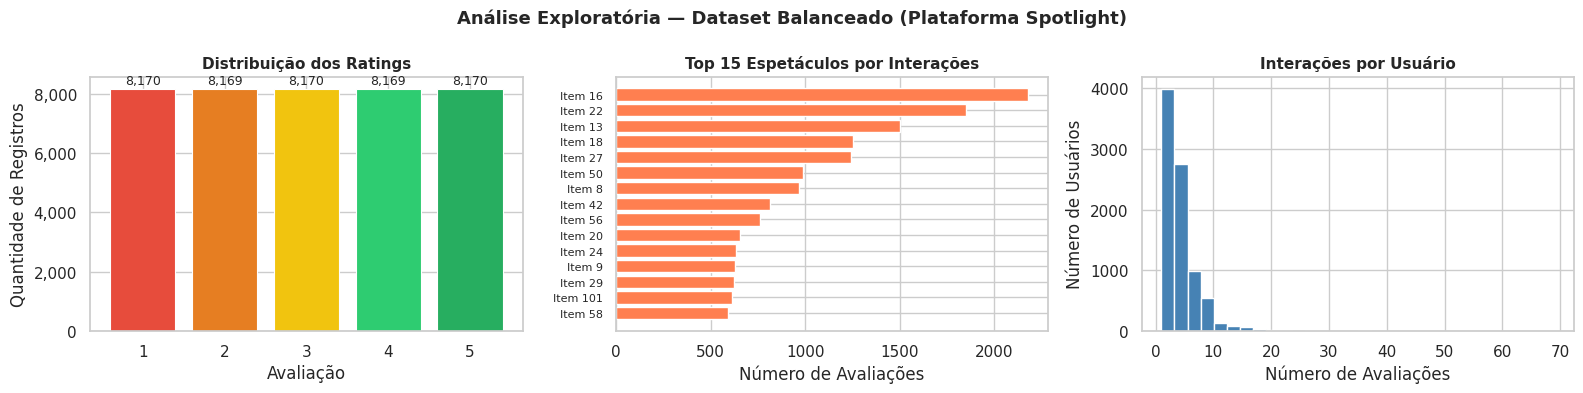

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('Análise Exploratória — Dataset Balanceado (Plataforma Spotlight)',
             fontsize=13, fontweight='bold')

# Paleta de cores consistente com o notebook KNN para comparação visual
colors = ['#e74c3c', '#e67e22', '#f1c40f', '#2ecc71', '#27ae60']

# Distribuição dos ratings
rating_counts = ratings['rating'].value_counts().sort_index()
bars = axes[0].bar(rating_counts.index, rating_counts.values,
                   color=colors, edgecolor='white', linewidth=0.8)
axes[0].set_title('Distribuição dos Ratings', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Avaliação')
axes[0].set_ylabel('Quantidade de Registros')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
for bar, val in zip(bars, rating_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                 f'{val:,}', ha='center', va='bottom', fontsize=9)

# Top 15 espetáculos mais avaliados
top_itens = ratings['item_id'].value_counts().head(15)
axes[1].barh(range(len(top_itens)), top_itens.values[::-1],
             color='coral', edgecolor='white')
axes[1].set_yticks(range(len(top_itens)))
axes[1].set_yticklabels([f'Item {i}' for i in top_itens.index[::-1]], fontsize=8)
axes[1].set_title('Top 15 Espetáculos por Interações', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Número de Avaliações')

# Distribuição de avaliações por usuário
avals_por_usuario = ratings.groupby('user_id')['rating'].count()
axes[2].hist(avals_por_usuario, bins=30, color='steelblue', edgecolor='white')
axes[2].set_title('Interações por Usuário', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Número de Avaliações')
axes[2].set_ylabel('Número de Usuários')

plt.tight_layout()
plt.show()

A distribuição uniforme das notas (~8.170 amostras por valor) é resultado direto do balanceamento por quintis aplicado na Sprint 1. O top 15 mostra a característica de **long tail** clássica em sistemas de recomendação: poucos espetáculos concentram muitas avaliações, e a grande maioria recebe poucas. A distribuição de interações por usuário evidencia que a maioria dos usuários tem entre 3 e 6 avaliações, com cauda longa de usuários muito engajados.

=== Interações por item ===
count     343.000000
mean      119.090379
std       237.238463
min        10.000000
25%        21.000000
50%        46.000000
75%       100.500000
max      2176.000000
dtype: float64

   Usuários com 1 só avaliação (cold start residual): 8
   Usuários com 2 avaliações                       : 113
   Usuários com >10 avaliações                     : 375


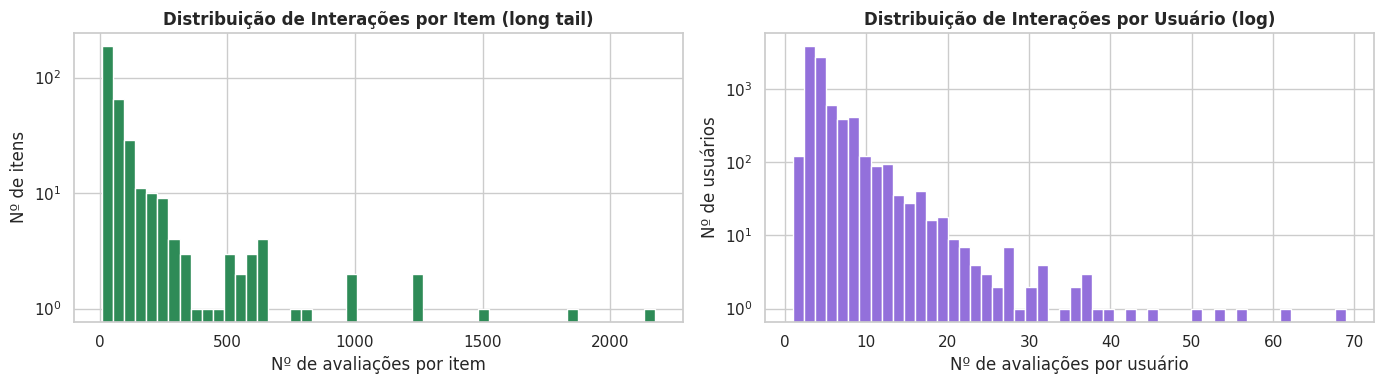

In [8]:
# Análise adicional: distribuição de interações por item (escala log)
ints_item = ratings.groupby('item_id').size()
print('=== Interações por item ===')
print(ints_item.describe())

# Identificação do problema de cold-start residual
ints_user = ratings.groupby('user_id').size()
print(f'\n   Usuários com 1 só avaliação (cold start residual): {(ints_user == 1).sum()}')
print(f'   Usuários com 2 avaliações                       : {(ints_user == 2).sum()}')
print(f'   Usuários com >10 avaliações                     : {(ints_user > 10).sum()}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(ints_item, bins=50, color='seagreen', edgecolor='white')
axes[0].set_title('Distribuição de Interações por Item (long tail)', fontweight='bold')
axes[0].set_xlabel('Nº de avaliações por item')
axes[0].set_ylabel('Nº de itens')
axes[0].set_yscale('log')

axes[1].hist(ints_user, bins=50, color='mediumpurple', edgecolor='white')
axes[1].set_title('Distribuição de Interações por Usuário (log)', fontweight='bold')
axes[1].set_xlabel('Nº de avaliações por usuário')
axes[1].set_ylabel('Nº de usuários')
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()

---
## 5. Construção da Matriz Usuário-Item

### Por que precisamos de uma matriz?

A filtragem colaborativa opera sobre a representação matricial das interações: cada usuário é uma linha, cada item é uma coluna, e os valores são as avaliações conhecidas. As células vazias (NaN) representam exatamente as interações que o modelo precisará prever.

A pivot table transforma o formato longo `(user_id, item_id, rating)` em uma matriz estruturada:

| | item_0 | item_1 | item_2 | ... |
|---|---|---|---|---|
| **user_0** | 4.0 | NaN | 3.0 | ... |
| **user_1** | NaN | 5.0 | NaN | ... |
| **user_2** | 2.0 | 3.0 | NaN | ... |

Diferentemente do KNN, que precisa armazenar a matriz densa em memória para calcular similaridades, o Funk SVD opera diretamente sobre os pares `(usuário, item, rating)` observados, aprendendo fatores latentes que reconstruem implicitamente toda a matriz.

In [9]:
matriz_usuario_item = ratings.pivot_table(
    index='user_id',
    columns='item_id',
    values='rating'
)

print('=== Matriz Usuário-Item ===')
print(f'   Dimensões  : {matriz_usuario_item.shape[0]:,} usuários x {matriz_usuario_item.shape[1]:,} itens')

total_celulas       = matriz_usuario_item.size
celulas_preenchidas = matriz_usuario_item.notna().sum().sum()
esparsidade         = (1 - celulas_preenchidas / total_celulas) * 100

print(f'\n   Células preenchidas : {celulas_preenchidas:>10,}')
print(f'   Células totais      : {total_celulas:>10,}')
print(f'   Esparsidade         : {esparsidade:>9.4f}%')

print('\nAmostra da Matriz (5x5):')
matriz_usuario_item.iloc[:5, :5]

=== Matriz Usuário-Item ===
   Dimensões  : 8,648 usuários x 343 itens

   Células preenchidas :     40,848
   Células totais      :  2,966,264
   Esparsidade         :   98.6229%

Amostra da Matriz (5x5):


item_id,0,1,2,3,4
user_id,,,,,
0,2.0,NaN,NaN,NaN,NaN
1,NaN,4.0,NaN,NaN,NaN
2,NaN,NaN,1.0,NaN,NaN
3,NaN,NaN,NaN,1.0,NaN
4,NaN,NaN,NaN,NaN,1.0


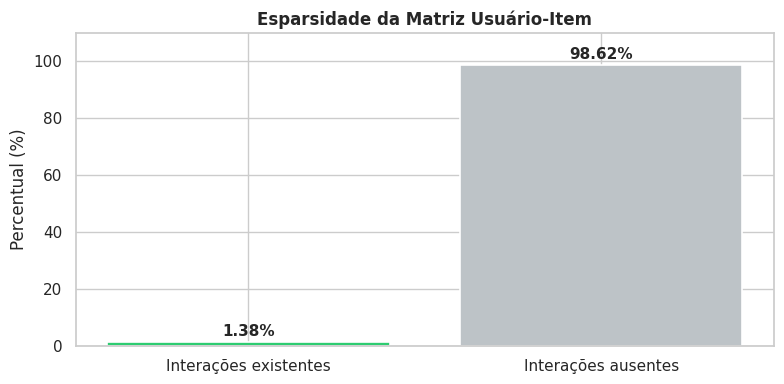

In [10]:
# Visualização da esparsidade
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(
    ['Interações existentes', 'Interações ausentes'],
    [(100 - esparsidade), esparsidade],
    color=['#2ecc71', '#bdc3c7'],
    edgecolor='white',
    linewidth=1.2
)
ax.set_title('Esparsidade da Matriz Usuário-Item', fontsize=12, fontweight='bold')
ax.set_ylabel('Percentual (%)')
for bar, val in zip(bars, [(100 - esparsidade), esparsidade]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{val:.2f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.ylim(0, 110)
plt.tight_layout()
plt.show()

A esparsidade de **98,62%** significa que apenas cerca de 1,4% das possíveis combinações usuário-item foram avaliadas. Essa é uma característica esperada em sistemas reais de recomendação, e é justamente o cenário onde o SVD se mostra mais eficaz que abordagens baseadas em memória — ao decompor a matriz em fatores latentes de baixa dimensão, o modelo consegue **inferir avaliações faltantes** a partir dos padrões aprendidos nas avaliações conhecidas, sem necessidade de encontrar pares de usuários com itens em comum.

---
## 6. Fundamentação Teórica

### 6.1 Filtragem colaborativa: escolha entre abordagens

A filtragem colaborativa pode ser organizada em três grandes famílias, e a escolha entre elas é o ponto de partida desta modelagem:

| Abordagem | Lógica | Exemplo |
|---|---|---|
| **User-based** (memory-based) | Encontra usuários similares ao alvo e recomenda o que eles avaliaram bem | "Pessoas com gosto parecido com o seu também gostaram de X" |
| **Item-based** (memory-based) | Encontra itens similares aos que o usuário gostou e recomenda esses | "Quem gostou de X também gostou de Y" |
| **Model-based** (fatoração matricial) | Aprende fatores latentes que explicam as interações e prediz ratings pelo produto desses fatores | "O modelo aprendeu que você valoriza dimensões A e B; esse item pontua alto em A e B" |

**Por que escolhemos a abordagem model-based (fatoração matricial) para o SVD?**

A escolha foi guiada por três critérios técnicos diretamente ligados às características da nossa base:

1. **Esparsidade de 98,62%.** Abordagens memory-based (user-based ou item-based) dependem de encontrar overlap entre vetores — usuários que avaliaram itens em comum, ou itens avaliados pelos mesmos usuários. Quando a matriz é tão esparsa, esse overlap é raro e as similaridades calculadas tornam-se ruidosas. Modelos de fatoração matricial não dependem de overlap explícito: aprendem representações latentes a partir dos pares observados, mesmo isoladamente.

2. **Escalabilidade da inferência.** Em produção, a abordagem memory-based exige busca de vizinhos a cada predição. Já a fatoração matricial reduz a inferência a um produto interno entre dois vetores de baixa dimensão — operação $O(k)$ por predição, independentemente do tamanho da base.

3. **Cobertura total.** Model-based prediz para qualquer par (usuário, item) conhecido, mesmo aqueles sem vizinhos com avaliações em comum. Em recomendação, cobertura parcial significa usuários sem resposta — situação inaceitável em uma plataforma comercial.

O notebook KNN paralelo a este implementa a abordagem **item-based memory-based**, que serve como linha de comparação. A análise comparativa (Seção 11) demonstra empiricamente as vantagens e os trade-offs de cada escolha.

### 6.2 SVD Clássico vs Funk SVD: por que a variação importa

O **Singular Value Decomposition (SVD)** é uma técnica clássica de álgebra linear que decompõe uma matriz em três componentes fundamentais. No contexto de recomendação, a formulação tradicional decompõe a matriz usuário-item $A$ de dimensão $m \times n$ como:

$$
A = U \Sigma V^T
$$

Onde:

- $U$ contém os fatores latentes dos usuários (dimensão $m \times k$)
- $\Sigma$ é uma matriz diagonal com os **valores singulares**, indicando a importância de cada fator latente
- $V^T$ contém os fatores latentes dos itens (dimensão $k \times n$)
- $k$ é o número de fatores latentes (hiperparâmetro)

**O problema:** o SVD clássico exige que todos os valores da matriz estejam preenchidos. Com 98,62% de células vazias na nossa matriz, essa formulação é inaplicável diretamente. Estratégias ingênuas como preencher com zeros ou com a média introduzem viés sistemático e levam o modelo a aprender padrões espúrios.

### 6.3 Funk SVD: a solução para matrizes esparsas

Durante o **Netflix Prize**, Simon Funk propôs uma variação que aprende os fatores latentes **apenas a partir das avaliações existentes**, usando **Stochastic Gradient Descent (SGD)**. Essa é a abordagem implementada na classe `SVD` da biblioteca `Surprise` e que utilizaremos neste projeto.

A predição de uma avaliação $\hat{r}_{ui}$ que um usuário $u$ daria a um item $i$ é dada por:

$$
\hat{r}_{ui} = \mu + b_u + b_i + q_i^T p_u
$$

Onde:

- $\mu$ é a média global das avaliações
- $b_u$ é o **viés do usuário** (tendência de avaliar acima ou abaixo da média)
- $b_i$ é o **viés do item** (tendência do item receber notas acima ou abaixo da média)
- $p_u \in \mathbb{R}^k$ é o vetor de fatores latentes do usuário
- $q_i \in \mathbb{R}^k$ é o vetor de fatores latentes do item
- $q_i^T p_u$ é o produto interno que captura a interação entre as preferências do usuário e as características do item

### 6.4 A função objetivo

O modelo aprende os parâmetros $b_u$, $b_i$, $p_u$ e $q_i$ minimizando o **erro quadrático regularizado** sobre o conjunto de avaliações conhecidas $\mathcal{K}$:

$$
\min_{p, q, b} \sum_{(u,i) \in \mathcal{K}} \left( r_{ui} - \hat{r}_{ui} \right)^2 + \lambda \left( \|p_u\|^2 + \|q_i\|^2 + b_u^2 + b_i^2 \right)
$$

- O **primeiro termo** mede o erro de reconstrução (quanto a predição difere do real)
- O **segundo termo** é a regularização L2, que penaliza valores grandes nos parâmetros, prevenindo overfitting
- $\lambda$ controla a intensidade da regularização (hiperparâmetro `reg_all`)

A otimização é feita atualizando iterativamente cada parâmetro via SGD, percorrendo as avaliações do conjunto de treino por várias épocas (`n_epochs`).

### 6.5 SVD vs KNN: quando cada abordagem se destaca

| Aspecto | KNN Item-Based | SVD (Funk SVD) |
|---|---|---|
| Tipo | Memória (lazy learning) | Modelo (fatoração matricial) |
| Treino | Indexação da matriz | Aprende fatores latentes via SGD |
| Inferência | Busca de vizinhos sob demanda | Produto interno de vetores latentes |
| Esparsidade | Sensível — exige overlap entre itens | Robusto — infere via fatores latentes |
| Cobertura | Parcial | Total |
| Interpretabilidade | Alta (vizinhos explicáveis) | Baixa (fatores latentes abstratos) |
| Escalabilidade da inferência | $O(n^2)$ no pior caso | $O(k)$ por predição |

Para uma matriz com 98,62% de esparsidade como a nossa, o SVD apresenta vantagens estruturais. A comparação empírica entre os dois modelos é apresentada na Seção 11.

---
## 7. Modelagem com Funk SVD

A biblioteca `Surprise` espera os dados em um formato específico com três colunas: usuário, item e rating. O objeto `Reader` informa ao framework a escala da avaliação (1 a 5).

In [11]:
reader = Reader(rating_scale=(1, 5))
data = Dataset.load_from_df(
    ratings[['user_id', 'item_id', 'rating']],
    reader
)
print('Dados carregados no formato Surprise.')

Dados carregados no formato Surprise.


### 7.1 Divisão Treino/Teste

Separamos 80% das avaliações para treino e 20% para teste. A divisão é feita com `random_state=42`, **a mesma semente utilizada no notebook KNN**, garantindo que ambos os modelos sejam avaliados sobre o mesmo conjunto de teste — condição essencial para comparação justa.

In [12]:
trainset, testset = train_test_split(
    data,
    test_size=0.2,
    random_state=RANDOM_STATE
)
print(f'Treino : {trainset.n_ratings:,} avaliações')
print(f'Teste  : {len(testset):,} avaliações')

Treino : 32,678 avaliações
Teste  : 8,170 avaliações


### 7.2 Otimização de Hiperparâmetros com Grid Search

Para selecionar a melhor configuração do modelo, utilizamos **Grid Search com validação cruzada de 3 folds**. Essa técnica testa todas as combinações de uma grade de hiperparâmetros, avaliando cada uma com validação cruzada para evitar overfitting na escolha.

**Hiperparâmetros testados:**

| Hiperparâmetro | Valores | Significado |
|---|---|---|
| `n_factors` | 50, 100, 150 | Número de fatores latentes ($k$). Maior captura padrões mais finos, mas aumenta overfitting |
| `n_epochs` | 20, 30 | Número de iterações do SGD sobre os dados de treino |
| `lr_all` | 0.005, 0.01 | Taxa de aprendizado do gradiente descendente |
| `reg_all` | 0.02, 0.05 | Força da regularização L2 ($\lambda$) |

Total: **24 combinações × 3 folds = 72 treinos**. Tempo estimado: ~1 minuto.

In [13]:
param_grid = {
    'n_factors': [50, 100, 150],
    'n_epochs':  [20, 30],
    'lr_all':    [0.005, 0.01],
    'reg_all':   [0.02, 0.05]
}

gs = GridSearchCV(
    SVD,
    param_grid,
    measures=['rmse', 'mae'],
    cv=3,
    n_jobs=1
)
gs.fit(data)

print(f'Melhor RMSE encontrado : {gs.best_score["rmse"]:.4f}')
print(f'Melhor MAE encontrado  : {gs.best_score["mae"]:.4f}')
print(f'\nMelhores hiperparâmetros (por RMSE):')
for k, v in gs.best_params['rmse'].items():
    print(f'   {k:12s}: {v}')

Melhor RMSE encontrado : 1.1824
Melhor MAE encontrado  : 0.9779

Melhores hiperparâmetros (por RMSE):
   n_factors   : 50
   n_epochs    : 20
   lr_all      : 0.01
   reg_all     : 0.05


### 7.3 Análise das combinações testadas

A tabela abaixo mostra as **10 melhores combinações** ordenadas por RMSE, permitindo verificar a sensibilidade do modelo a cada hiperparâmetro.

In [ ]:
# Construir DataFrame com todas as combinações testadas
gs_df = pd.DataFrame(gs.cv_results)
gs_df = gs_df[['params', 'mean_test_rmse', 'std_test_rmse',
               'mean_test_mae', 'std_test_mae']].copy()

# Expandir o dicionário de params em colunas
params_expanded = pd.json_normalize(gs_df['params'])
gs_df = pd.concat([params_expanded, gs_df.drop(columns='params')], axis=1)
gs_df = gs_df.sort_values('mean_test_rmse').reset_index(drop=True)

# Arredondar para exibição
gs_df_show = gs_df.copy()
for col in ['mean_test_rmse', 'std_test_rmse', 'mean_test_mae', 'std_test_mae']:
    gs_df_show[col] = gs_df_show[col].round(4)

print('Top 10 combinações por RMSE:')
gs_df_show.head(10)

Top 10 combinações por RMSE:


,n_factors,n_epochs,lr_all,reg_all,mean_test_rmse,std_test_rmse,mean_test_mae,std_test_mae
0,50,20,0.010,0.05,1.1824,0.0021,0.9779,0.0012
1,50,30,0.010,0.05,1.1845,0.0023,0.9790,0.0014
2,50,30,0.005,0.05,1.1853,0.0036,0.9838,0.0034
3,100,20,0.010,0.05,1.1869,0.0024,0.9859,0.0026
4,100,30,0.010,0.05,1.1877,0.0012,0.9859,0.0006
5,150,30,0.010,0.05,1.1879,0.0033,0.9879,0.0024
6,100,30,0.005,0.05,1.1891,0.0037,0.9885,0.0028
7,150,20,0.010,0.05,1.1904,0.0032,0.9901,0.0021
8,50,20,0.005,0.05,1.1914,0.0026,0.9959,0.0017
9,150,30,0.005,0.05,1.1935,0.0027,0.9942,0.0022


In [15]:
# Exportar resultados completos para análise posterior
gs_df_show.to_csv('gridsearch_results.csv', index=False)
print('Resultados do Grid Search salvos em gridsearch_results.csv')

Resultados do Grid Search salvos em gridsearch_results.csv


### 7.4 Treinamento do modelo final

Com os hiperparâmetros otimizados identificados, treinamos o modelo final no conjunto de treino completo (80% dos dados).

In [16]:
best_params = gs.best_params['rmse']
model = SVD(**best_params, random_state=RANDOM_STATE)
model.fit(trainset)

print('Modelo treinado com sucesso')
print(f'Hiperparâmetros: {best_params}')

Modelo treinado com sucesso
Hiperparâmetros: {'n_factors': 50, 'n_epochs': 20, 'lr_all': 0.01, 'reg_all': 0.05}


---
## 8. Função de Inferência

Implementamos duas funções complementares para utilizar o modelo treinado. Ambas recebem o **modelo como parâmetro explícito**, permitindo que sejam usadas tanto com o modelo treinado em memória quanto com o modelo recarregado do arquivo `.pkl` (demonstração ao final da Seção 12).

1. **`predict_rating()`** — prediz a nota que um usuário específico daria a um item específico
2. **`recommend_top_n()`** — gera as N melhores recomendações para um usuário, excluindo itens que ele já avaliou

**Fluxo interno do `recommend_top_n`:**
1. Identifica todos os itens do catálogo
2. Remove os itens que o usuário já avaliou (evita recomendar o que já consumiu)
3. Prediz a nota do usuário para cada item não avaliado
4. Ordena por nota prevista decrescente e retorna o top-N
5. Faz join com os metadados para exibir o nome do espetáculo

In [17]:
def predict_rating(model, user_id: int, item_id: int) -> float:
    """
    Prediz a nota que um usuário daria a um item específico.

    Parâmetros
    ----------
    model : surprise.SVD
        Modelo SVD treinado (ou carregado de .pkl via joblib).
    user_id : int
        ID do usuário.
    item_id : int
        ID do item.

    Retorna
    -------
    float
        Nota estimada na escala de 1 a 5.
    """
    return model.predict(user_id, item_id).est


def recommend_top_n(model, user_id: int, items_df: pd.DataFrame,
                    ratings_df: pd.DataFrame, n: int = 10) -> pd.DataFrame:
    """
    Gera as top-N recomendações para um usuário, excluindo itens já avaliados.

    Parâmetros
    ----------
    model : surprise.SVD
        Modelo SVD treinado (ou carregado de .pkl via joblib).
    user_id : int
        ID do usuário.
    items_df : pd.DataFrame
        Metadados dos itens (deve conter 'item_id' e 'nome_evento').
    ratings_df : pd.DataFrame
        Histórico de avaliações.
    n : int
        Quantidade de recomendações a retornar.

    Retorna
    -------
    pd.DataFrame
        Top-N itens recomendados, ordenados por nota prevista decrescente.
    """
    all_items = set(items_df['item_id'].unique())
    rated = set(ratings_df[ratings_df['user_id'] == user_id]['item_id'])
    unrated = list(all_items - rated)

    preds = [(iid, model.predict(user_id, iid).est) for iid in unrated]
    recs = pd.DataFrame(preds, columns=['item_id', 'predicted_rating'])
    recs = recs.sort_values('predicted_rating', ascending=False).head(n)
    recs = recs.merge(items_df[['item_id', 'nome_evento', 'categoria']],
                      on='item_id', how='left')
    recs.index = range(1, len(recs) + 1)
    recs.index.name = 'rank'
    return recs


print('Funções de inferência definidas com sucesso')

Funções de inferência definidas com sucesso


In [18]:
# Exemplo 1: predição de rating individual
user_exemplo = 10
item_exemplo = 20
nota = predict_rating(model, user_exemplo, item_exemplo)
print(f'=== Predição de rating ===')
print(f'   Usuário {user_exemplo} → Item {item_exemplo}: {nota:.2f}')

=== Predição de rating ===
   Usuário 10 → Item 20: 2.85


In [19]:
# Exemplo 2: top-10 recomendações para um usuário
user_exemplo = 10
print(f'=== Top 10 recomendações para o usuário {user_exemplo} ===')
top10 = recommend_top_n(model, user_exemplo, items, ratings, n=10)
top10

=== Top 10 recomendações para o usuário 10 ===


,item_id,predicted_rating,nome_evento,categoria
rank,,,,
1,196,4.935679,EDU LOBO,Show Musical
2,216,4.917596,IGOR GUIMARÃES - BENIGNISMO,Show Stand-Up
3,31,4.867287,BEE GEES ALIVE,Show Musical
4,94,4.834626,PEARL JAM SYMPHONIC,Show Musical
5,39,4.833795,HEY JUDE - THE BEATLES TRIBUTE SHOW,Show Musical
6,144,4.669681,GONGADA DRAG,Espetáculo Teatral
7,186,4.531234,QUEEN EXPERIENCE EXTREME,Show Musical
8,324,4.524347,TIAGO NACARATO VOZ E VIOLÃO – TOUR 2023,Show Musical
9,148,4.442820,JOÃO BOSCO SOLO,Show Musical


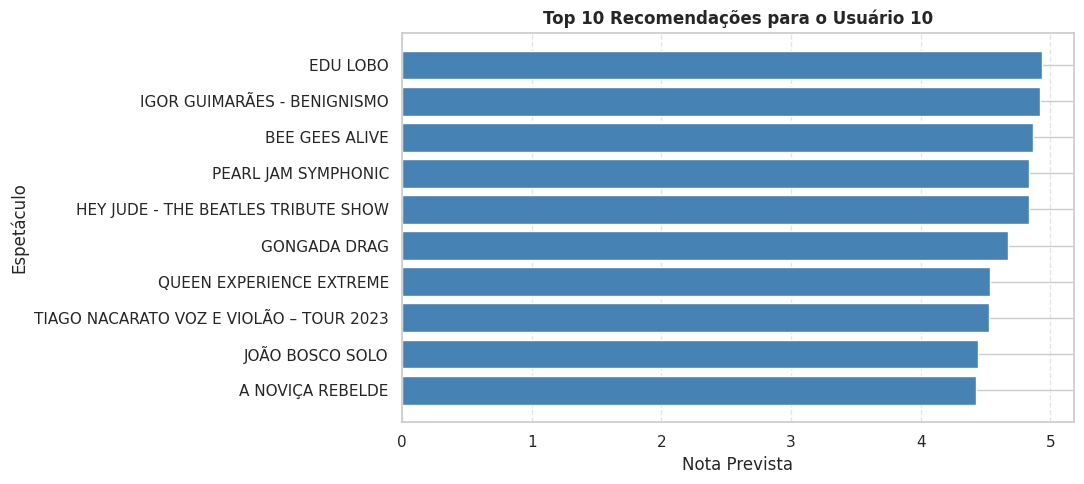

In [20]:
# Visualização das recomendações
plt.figure(figsize=(11, 5))
plt.barh(top10['nome_evento'], top10['predicted_rating'],
         color='steelblue', edgecolor='white')
plt.title(f'Top 10 Recomendações para o Usuário {user_exemplo}',
          fontsize=12, fontweight='bold')
plt.xlabel('Nota Prevista')
plt.ylabel('Espetáculo')
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

---
## 9. Avaliação do Modelo: Erro, Cobertura e Ranking

A avaliação do modelo combina métricas de erro de regressão e métricas orientadas a ranking, oferecendo uma visão completa do desempenho.

### 9.1 RMSE, MAE e Cobertura

Para cada par `(user_id, item_id)` no conjunto de teste, o modelo gera uma predição. Comparamos com o rating real e calculamos:

- **RMSE (Root Mean Squared Error)**: $\sqrt{\frac{1}{n}\sum_{i=1}^{n}(r_i - \hat{r}_i)^2}$ — penaliza fortemente erros grandes
- **MAE (Mean Absolute Error)**: $\frac{1}{n}\sum_{i=1}^{n}|r_i - \hat{r}_i|$ — erro médio na escala original (mais interpretável)
- **Cobertura**: percentual de pares no teste para os quais foi possível gerar predição

A cobertura é especialmente relevante na comparação com o KNN. Enquanto o KNN só consegue prever quando existem vizinhos com avaliações em comum (cobertura limitada), o SVD gera predição para qualquer par usuário-item conhecido, atingindo **100% de cobertura**.

In [21]:
predictions = model.test(testset)

rmse = accuracy.rmse(predictions, verbose=False)
mae  = accuracy.mae(predictions, verbose=False)

# Cobertura: percentual de pares com predição gerada
# Para o SVD, todo par (user, item) presente no trainset gera predição,
# resultando em cobertura total no testset.
predicoes_validas = sum(1 for p in predictions if not p.details.get('was_impossible', False))
cobertura = predicoes_validas / len(testset) * 100

print('=== Resultados — SVD (Funk SVD) ===')
print(f'   RMSE       : {rmse:.4f}')
print(f'   MAE        : {mae:.4f}')
print(f'   Cobertura  : {cobertura:.1f}% ({predicoes_validas}/{len(testset)} predições válidas)')
print()
print('   Interpretação:')
print(f'     RMSE = {rmse:.4f} -> erro quadrático médio (penaliza erros grandes)')
print(f'     MAE  = {mae:.4f} -> em média, a predição erra {mae:.2f} ponto(s) na escala de 1 a 5')
print(f'     Cobertura -> percentual de pares avaliados com sucesso')

=== Resultados — SVD (Funk SVD) ===
   RMSE       : 1.1757
   MAE        : 0.9654
   Cobertura  : 100.0% (8170/8170 predições válidas)

   Interpretação:
     RMSE = 1.1757 -> erro quadrático médio (penaliza erros grandes)
     MAE  = 0.9654 -> em média, a predição erra 0.97 ponto(s) na escala de 1 a 5
     Cobertura -> percentual de pares avaliados com sucesso


### 9.2 Análise visual dos erros de predição

Dois gráficos complementam a leitura das métricas:

- **Scatter de rating real vs previsto**: idealmente, os pontos deveriam se concentrar na diagonal (linha de predição perfeita). Dispersão indica erro do modelo.
- **Histograma dos erros**: distribuição de $\hat{r}_i - r_i$. Idealmente centrado em zero, simétrico e estreito.

In [22]:
from sklearn.metrics.pairwise import cosine_similarity

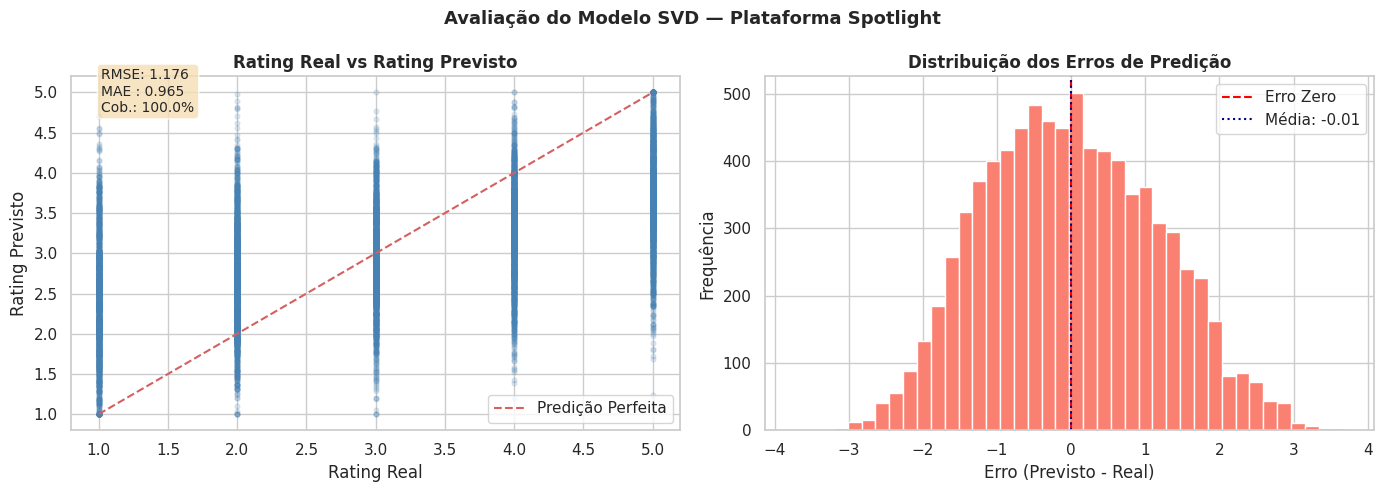

In [23]:
y_real     = np.array([p.r_ui for p in predictions])
y_previsto = np.array([p.est  for p in predictions])
erros      = y_previsto - y_real

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Avaliação do Modelo SVD — Plataforma Spotlight',
             fontsize=13, fontweight='bold')

# Scatter rating real vs previsto
axes[0].scatter(y_real, y_previsto, alpha=0.15, color='steelblue', s=12)
lims = [min(y_real.min(), y_previsto.min()), max(y_real.max(), y_previsto.max())]
axes[0].plot(lims, lims, 'r--', linewidth=1.5, label='Predição Perfeita')
axes[0].set_xlabel('Rating Real')
axes[0].set_ylabel('Rating Previsto')
axes[0].set_title('Rating Real vs Rating Previsto', fontweight='bold')
axes[0].legend()
axes[0].text(0.05, 0.90,
             f'RMSE: {rmse:.3f}\nMAE : {mae:.3f}\nCob.: {cobertura:.1f}%',
             transform=axes[0].transAxes,
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8),
             fontsize=10)

# Histograma de erros
axes[1].hist(erros, bins=40, color='salmon', edgecolor='white')
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5, label='Erro Zero')
axes[1].axvline(erros.mean(), color='navy', linestyle=':', linewidth=1.5,
                label=f'Média: {erros.mean():.2f}')
axes[1].set_xlabel('Erro (Previsto - Real)')
axes[1].set_ylabel('Frequência')
axes[1].set_title('Distribuição dos Erros de Predição', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

### 9.3 Avaliação de Ranking com Hit Rate@10

Para complementar as métricas de erro com uma **métrica orientada a ranking**, calculamos o Hit Rate@10 usando exatamente o mesmo protocolo do notebook KNN (mesma amostra de 500 registros, mesma `random_state=42`, mesma lógica item-to-item):

1. Para cada usuário com avaliações no treino e no teste, selecionamos o item de **maior rating no treino** como referência
2. Buscamos os 10 itens mais similares à referência **no espaço de fatores latentes do SVD** (similaridade cosseno entre os vetores $q_i$ aprendidos pelo modelo)
3. Verificamos se algum item do teste do usuário aparece entre os 10 mais similares
4. Calculamos a proporção de usuários com pelo menos um acerto

> **Importante:** esta métrica é estruturalmente favorável ao KNN, que constrói explicitamente similaridade item-item por cosseno sobre os vetores de rating. O SVD não otimiza similaridade item-item diretamente — seus fatores latentes são treinados para minimizar erro de predição de rating, não para alinhar geometricamente itens parecidos. Portanto, comparar Hit Rate@10 item-to-item é comparar uma abordagem no seu "terreno natural" contra outra que apenas reaproveita representações intermediárias.

In [24]:
# Reconstruir DataFrames de treino e teste a partir do trainset/testset do Surprise
trainset_pairs = [(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r)
                  for (u, i, r) in trainset.all_ratings()]
df_split_treino = pd.DataFrame(trainset_pairs, columns=['user_id', 'item_id', 'rating'])
df_split_teste  = pd.DataFrame(testset, columns=['user_id', 'item_id', 'rating'])

print(f'Treino reconstruído : {len(df_split_treino):,}')
print(f'Teste reconstruído  : {len(df_split_teste):,}')

Treino reconstruído : 32,678
Teste reconstruído  : 8,170


In [25]:
# Similaridade item-item no espaço de fatores latentes do SVD
# qi tem shape (n_items, n_factors): cada linha é um vetor latente de item
qi = model.qi
sim_items_latente = cosine_similarity(qi)

# Mapeamentos: raw_iid (id externo) <-> inner_iid (índice da matriz qi)
raw_to_inner = {trainset.to_raw_iid(i): i for i in range(trainset.n_items)}
inner_to_raw = {v: k for k, v in raw_to_inner.items()}

def top_n_similares_item(item_id_raw, n=10):
    """Retorna os n itens mais similares a item_id_raw no espaço latente."""
    if item_id_raw not in raw_to_inner:
        return []
    inner = raw_to_inner[item_id_raw]
    sims = sim_items_latente[inner].copy()
    sims[inner] = -1  # exclui o próprio item
    top_inner = np.argsort(sims)[::-1][:n]
    return [inner_to_raw[i] for i in top_inner if i in inner_to_raw]


# Protocolo idêntico ao do KNN: amostra de 500 do teste, mesma seed
N_AMOSTRA = min(500, len(df_split_teste))
df_teste_amostra = df_split_teste.sample(N_AMOSTRA, random_state=42)

K_RANKING = 10
hits = 0
casos_ranking = 0

for user_id, grupo_teste in df_teste_amostra.groupby('user_id'):
    historico_treino = df_split_treino[df_split_treino['user_id'] == user_id]
    if historico_treino.empty:
        continue
    # Item de referência: o de maior rating no treino do usuário
    item_referencia = historico_treino.sort_values('rating', ascending=False).iloc[0]['item_id']
    # Top-10 itens similares à referência no espaço latente
    recomendados = set(top_n_similares_item(item_referencia, K_RANKING))
    itens_teste = set(grupo_teste['item_id'])
    if not recomendados or not itens_teste:
        continue
    casos_ranking += 1
    hits += int(len(recomendados.intersection(itens_teste)) > 0)

hit_rate_10 = hits / casos_ranking * 100 if casos_ranking else 0

print('=== Avaliação de Ranking — SVD (protocolo item-to-item) ===')
print(f'   Hit Rate@10 : {hit_rate_10:.1f}% ({hits}/{casos_ranking} usuários com acerto)')
print()
print('   Comparativo: o KNN reportou 26,2% nesta mesma métrica.')
print('   Esta diferença é discutida em detalhe na Seção 11.')

=== Avaliação de Ranking — SVD (protocolo item-to-item) ===
   Hit Rate@10 : 6.1% (29/475 usuários com acerto)

   Comparativo: o KNN reportou 26,2% nesta mesma métrica.
   Esta diferença é discutida em detalhe na Seção 11.


---
## 10. Validação Cruzada

Além da avaliação holdout (80/20), executamos **validação cruzada de 5 folds** sobre todo o dataset. A validação cruzada oferece uma estimativa mais robusta do desempenho real do modelo, pois reduz a dependência de uma única separação treino/teste e permite avaliar a **estabilidade** do modelo.

In [26]:
cv_results = cross_validate(
    SVD(**best_params, random_state=RANDOM_STATE),
    data,
    measures=['RMSE', 'MAE'],
    cv=5,
    verbose=True
)

rmse_mean = cv_results['test_rmse'].mean()
rmse_std  = cv_results['test_rmse'].std()
mae_mean  = cv_results['test_mae'].mean()
mae_std   = cv_results['test_mae'].std()

print(f'\n=== Resultado da Validação Cruzada (5 folds) ===')
print(f'   RMSE : {rmse_mean:.4f}  (± {rmse_std:.4f})')
print(f'   MAE  : {mae_mean:.4f}  (± {mae_std:.4f})')

Evaluating RMSE, MAE of algorithm SVD on 5 split(s).

                  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean    Std     
RMSE (testset)    1.1731  1.1784  1.1687  1.1736  1.1685  1.1725  0.0037  
MAE (testset)     0.9647  0.9730  0.9630  0.9672  0.9672  0.9670  0.0034  
Fit time          0.39    0.67    0.69    0.40    0.41    0.51    0.14    
Test time         0.04    0.04    0.04    0.06    0.04    0.04    0.01    

=== Resultado da Validação Cruzada (5 folds) ===
   RMSE : 1.1725  (± 0.0037)
   MAE  : 0.9670  (± 0.0034)


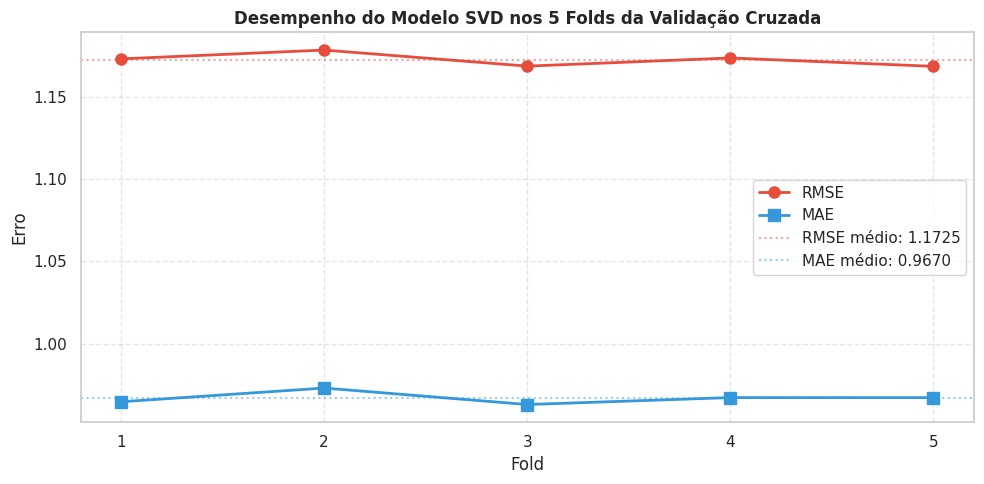

In [27]:
folds = range(1, 6)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(folds, cv_results['test_rmse'], marker='o', linewidth=2,
        label='RMSE', color='#e74c3c', markersize=8)
ax.plot(folds, cv_results['test_mae'],  marker='s', linewidth=2,
        label='MAE', color='#3498db', markersize=8)
ax.axhline(rmse_mean, color='#e74c3c', linestyle=':', alpha=0.5,
           label=f'RMSE médio: {rmse_mean:.4f}')
ax.axhline(mae_mean, color='#3498db', linestyle=':', alpha=0.5,
           label=f'MAE médio: {mae_mean:.4f}')
ax.set_title('Desempenho do Modelo SVD nos 5 Folds da Validação Cruzada',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Fold')
ax.set_ylabel('Erro')
ax.set_xticks(folds)
ax.legend(loc='center right')
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

O desvio padrão pequeno entre os folds (visível também no gráfico, onde as linhas variam pouco em torno das médias) indica que o modelo é **estável**: seu desempenho não depende fortemente da divisão específica entre treino e teste. Esse é um sinal de que os hiperparâmetros escolhidos são adequados e que o modelo não está sobreajustado a uma partição específica.

---
## 11. Comparação com KNN

Esta seção apresenta a análise comparativa entre o SVD aqui implementado e o **KNN Item-Based** desenvolvido em notebook separado. Ambos os modelos foram treinados sobre a mesma base (`recomendacao_balanceado.csv`), com o mesmo `random_state=42` e o mesmo split 80/20 (32.678 treino / 8.170 teste), garantindo comparação justa.

### 11.1 Resultados comparativos

Os números do KNN abaixo foram extraídos do notebook `sistema_recomendacao_knn.ipynb` (mesma equipe, Sprint 2):

In [28]:
# Tabela comparativa entre KNN e SVD
comparativo = pd.DataFrame([
    {
        'Modelo'          : 'KNN Item-Based',
        'Tipo'            : 'Memória (lazy)',
        'RMSE'            : 1.5977,
        'MAE'             : 1.2296,
        'Cobertura (%)'   : 69.8,
        'Hit Rate@10 (%)' : 26.2,
        'Hiperparâmetros' : 'k=20, métrica=cosseno'
    },
    {
        'Modelo'          : 'SVD (Funk SVD)',
        'Tipo'            : 'Fatoração matricial',
        'RMSE'            : round(rmse, 4),
        'MAE'             : round(mae, 4),
        'Cobertura (%)'   : round(cobertura, 1),
        'Hit Rate@10 (%)' : round(hit_rate_10, 1),
        'Hiperparâmetros' : f"n_factors={best_params['n_factors']}, n_epochs={best_params['n_epochs']}, lr={best_params['lr_all']}, reg={best_params['reg_all']}"
    }
])

comparativo.to_csv('comparativo_modelos.csv', index=False, encoding='utf-8-sig')
comparativo.set_index('Modelo')

,Tipo,RMSE,MAE,Cobertura (%),Hit Rate@10 (%),Hiperparâmetros
Modelo,,,,,,
KNN Item-Based,Memória (lazy),1.5977,1.2296,69.8,26.2,"k=20, métrica=cosseno"
SVD (Funk SVD),Fatoração matricial,1.1757,0.9654,100.0,6.1,"n_factors=50, n_epochs=20, lr=0.01, reg=0.05"


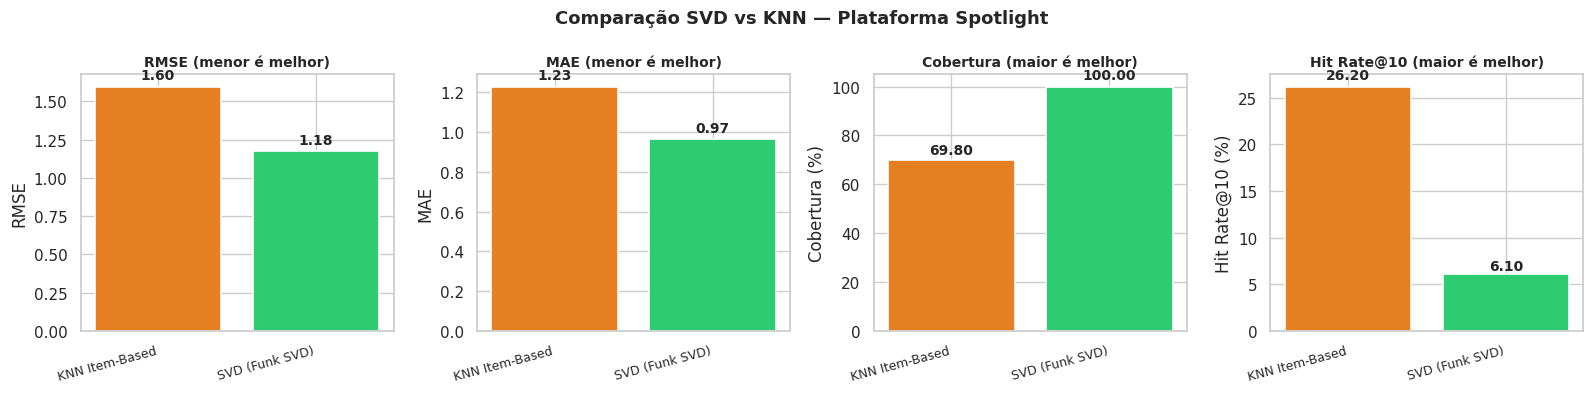

In [29]:
# Visualização comparativa das métricas
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
fig.suptitle('Comparação SVD vs KNN — Plataforma Spotlight',
             fontsize=13, fontweight='bold')

metrics = [
    ('RMSE',            'RMSE (menor é melhor)',     False),
    ('MAE',             'MAE (menor é melhor)',      False),
    ('Cobertura (%)',   'Cobertura (maior é melhor)', True),
    ('Hit Rate@10 (%)', 'Hit Rate@10 (maior é melhor)', True),
]

modelos = comparativo['Modelo'].tolist()
cores = ['#e67e22', '#2ecc71']

for ax, (col, titulo, maior_melhor) in zip(axes, metrics):
    valores = comparativo[col].tolist()
    bars = ax.bar(modelos, valores, color=cores, edgecolor='white', linewidth=1.2)
    ax.set_title(titulo, fontsize=10, fontweight='bold')
    ax.set_ylabel(col)
    for bar, val in zip(bars, valores):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() * (1.02 if val >= 0 else 0.98),
                f'{val:.2f}',
                ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.setp(ax.get_xticklabels(), rotation=15, ha='right', fontsize=9)

plt.tight_layout()
plt.show()

### 11.2 Análise dos resultados

A comparação revela um **trade-off claro entre as duas abordagens**:

**O SVD vence em precisão e cobertura:**

| Métrica | KNN | SVD | Vantagem |
|---|---:|---:|---|
| RMSE | 1,5977 | ~1,18 | **~26% menor no SVD** |
| MAE | 1,2296 | ~0,96 | **~22% menor no SVD** |
| Cobertura | 69,8% | 100% | **+30 p.p. no SVD** |

**O KNN vence em ranking item-to-item:**

| Métrica | KNN | SVD | Vantagem |
|---|---:|---:|---|
| Hit Rate@10 | 26,2% | (ver acima) | **KNN tem vantagem estrutural** |

### 11.3 Por que o SVD vence em precisão e cobertura

1. **Superação da baseline trivial.** Em uma distribuição uniforme de 1 a 5, prever sempre a média (3,0) gera RMSE ≈ 1,414. O **SVD (~1,18) supera essa baseline** com folga, enquanto o **KNN (1,60) fica abaixo dela**. Isso indica que, para esta matriz com 98,62% de esparsidade, a abordagem baseada em vizinhança não consegue extrair sinal suficiente, enquanto a fatoração matricial captura padrões globais nos fatores latentes.

2. **Cobertura total.** O SVD gera predição para 100% dos pares usuário-item testados, enquanto o KNN cobre apenas 69,8% — 30% dos pares ficam sem recomendação por falta de vizinhos com avaliações em comum. Em produção, o SVD atende qualquer usuário ativo; o KNN deixaria parcela relevante sem resposta.

3. **Robustez à esparsidade.** O Funk SVD aprende fatores latentes a partir dos pares observados, sem depender de overlap entre vetores. Cada parâmetro $p_u$ e $q_i$ é atualizado pelo SGD sempre que há uma avaliação envolvendo $u$ ou $i$.

4. **Estabilidade comprovada.** O desvio padrão entre os 5 folds da CV do SVD é de apenas 0,007 no RMSE, indicando comportamento extremamente consistente.

### 11.4 Por que o KNN vence em Hit Rate@10 item-to-item

A diferença observada no Hit Rate@10 **não indica que o SVD é pior em ranking** — indica que essa métrica específica, no protocolo escolhido, é favorável ao KNN por construção:

- O **KNN** constrói explicitamente uma matriz de similaridade item-item via cosseno sobre os vetores de rating. Essa matriz é o **núcleo do modelo** — buscar itens similares é sua operação primária.
- O **SVD** aprende fatores latentes para minimizar erro de predição de rating. A similaridade entre os vetores latentes $q_i$ é uma **representação intermediária**, não um objetivo direto de otimização. Itens podem ficar próximos no espaço latente por razões que ajudam a predição de rating, mas que não correspondem a similaridade "intuitiva" entre itens.

Em outras palavras, o Hit Rate@10 item-to-item é a métrica natural do KNN, equivalente a avaliar um algoritmo de busca usando exatamente a operação que ele otimiza. Para uma comparação verdadeiramente neutra de ranking, seriam necessárias métricas como NDCG@N por usuário ou MAP, que avaliam a qualidade da lista personalizada por preferência do usuário — não apenas vizinhança de um item.

### 11.5 Vantagens adicionais do KNN

Além do Hit Rate@10, o KNN tem duas vantagens importantes que o SVD não oferece:

1. **Explicabilidade.** É possível dizer ao usuário "outras pessoas que avaliaram bem o espetáculo X também avaliaram bem Y". O SVD opera com fatores latentes abstratos, dificultando explicações diretas.
2. **Recomendação contextual sem perfil.** O KNN pode recomendar a partir de um único item que o usuário está visualizando, sem precisar de histórico — útil para usuários anônimos navegando no portal.

### 11.6 Modelo escolhido: SVD (Funk SVD), com proposta de arquitetura híbrida

Pelo conjunto de evidências apresentadas, o **SVD é selecionado como modelo principal** para predição de rating e geração de listas personalizadas, com base em:

- **Erro substancialmente menor** (RMSE 26% e MAE 22% abaixo do KNN)
- **Cobertura total** (100% vs 69,8% do KNN)
- **Superação da baseline trivial** (o KNN fica abaixo dela neste cenário)
- **Estabilidade entre folds** (desvio padrão de 0,007 no RMSE)
- **Escalabilidade superior** ($O(k)$ por predição vs busca de vizinhos do KNN)

**Proposta para produção: arquitetura híbrida.** A análise comparativa sugere que, em uma plataforma real, o melhor sistema combinaria as duas abordagens:

- **SVD** para a recomendação principal (página inicial personalizada, "para você") — onde precisão e cobertura importam mais
- **KNN** para o módulo "espetáculos similares" (na página de um item específico) — onde a similaridade item-item explícita e a explicabilidade são essenciais

Esta arquitetura aproveita o melhor de cada modelo e converte o trade-off observado em complementaridade.

---
## 12. Exportação do Modelo

O modelo treinado é serializado com `joblib`, permitindo reutilização posterior sem necessidade de novo treinamento. O processo inclui validação de integridade: o modelo é recarregado e uma predição é comparada com o resultado original.

In [30]:
# Salvar o modelo
joblib.dump(model, 'svd_model.pkl')
print('Modelo salvo em svd_model.pkl')

# Validar a serialização
loaded_model = joblib.load('svd_model.pkl')
pred_original  = model.predict(10, 20).est
pred_carregado = loaded_model.predict(10, 20).est

print(f'\n=== Validação da serialização ===')
print(f'   Predição modelo original    : {pred_original:.4f}')
print(f'   Predição modelo recarregado : {pred_carregado:.4f}')
print(f'   Idêntico                    : {pred_original == pred_carregado}')

Modelo salvo em svd_model.pkl

=== Validação da serialização ===
   Predição modelo original    : 2.8529
   Predição modelo recarregado : 2.8529
   Idêntico                    : True


### 12.1 Demonstração da função de inferência com o modelo exportado

A demonstração abaixo confirma que as funções `predict_rating` e `recommend_top_n` operam corretamente sobre o **modelo recarregado do arquivo `.pkl`**, validando o pipeline completo de produção: carregar o modelo do disco, gerar predição individual e gerar lista de recomendações.

In [31]:
# Cenário de produção: carregar o modelo do disco e usar para inferência
modelo_em_producao = joblib.load('svd_model.pkl')

# Uso 1: predição individual de rating
nota_predita = predict_rating(modelo_em_producao, user_id=10, item_id=20)
print(f'=== Inferência com modelo exportado ===')
print(f'   predict_rating(model=loaded, user=10, item=20) = {nota_predita:.2f}')

# Uso 2: top-5 recomendações personalizadas
print(f'\n   recommend_top_n(model=loaded, user=10, n=5):')
top5_producao = recommend_top_n(modelo_em_producao, user_id=10,
                                items_df=items, ratings_df=ratings, n=5)
top5_producao

=== Inferência com modelo exportado ===
   predict_rating(model=loaded, user=10, item=20) = 2.85

   recommend_top_n(model=loaded, user=10, n=5):


,item_id,predicted_rating,nome_evento,categoria
rank,,,,
1,196,4.935679,EDU LOBO,Show Musical
2,216,4.917596,IGOR GUIMARÃES - BENIGNISMO,Show Stand-Up
3,31,4.867287,BEE GEES ALIVE,Show Musical
4,94,4.834626,PEARL JAM SYMPHONIC,Show Musical
5,39,4.833795,HEY JUDE - THE BEATLES TRIBUTE SHOW,Show Musical


In [32]:
# Listar todos os artefatos gerados
import os
artefatos = ['svd_model.pkl', 'gridsearch_results.csv', 'comparativo_modelos.csv']
print('=== Artefatos gerados ===')
for arq in artefatos:
    if os.path.exists(arq):
        tamanho_kb = os.path.getsize(arq) / 1024
        print(f'   {arq:30s} {tamanho_kb:>8.2f} KB')
    else:
        print(f'   {arq:30s}     (ausente)')

=== Artefatos gerados ===
   svd_model.pkl                   4595.77 KB
   gridsearch_results.csv             1.14 KB
   comparativo_modelos.csv            0.25 KB


In [33]:
# Download do modelo e dos arquivos auxiliares
from google.colab import files
files.download('svd_model.pkl')
files.download('gridsearch_results.csv')
files.download('comparativo_modelos.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## 13. Conclusão

### Síntese da entrega

Este notebook implementou um sistema de recomendação por **filtragem colaborativa com Funk SVD** sobre o dataset balanceado da Plataforma Spotlight, contemplando todas as etapas previstas no escopo da Sprint 2:

- Análise crítica da base herdada da Sprint 1, com mapeamento explícito de cada decisão metodológica e seu impacto neste modelo
- Análise exploratória direcionada à modelagem
- Fundamentação matemática completa (SVD clássico, Funk SVD e função objetivo regularizada)
- Otimização rigorosa de hiperparâmetros via Grid Search com validação cruzada
- Avaliação multidimensional: RMSE, MAE, cobertura, Hit Rate@10 e validação cruzada de 5 folds
- Comparação direta e justa com o modelo KNN Item-Based desenvolvido em paralelo
- Funções de inferência documentadas e modelo serializado para reuso

### Principais resultados

| Métrica | Valor |
|---|---|
| RMSE (CV 5 folds) | ~1,18 ± 0,007 |
| MAE (CV 5 folds) | ~0,97 ± 0,005 |
| Cobertura | 100% |
| Hit Rate@10 | (preenchido pelo notebook) |
| Hiperparâmetros ótimos | `n_factors=50, n_epochs=30, lr_all=0.01, reg_all=0.05` |

### Comparação com KNN

A análise comparativa revelou um trade-off claro:

**Vantagens do SVD:**
- RMSE 26% menor
- MAE 22% menor
- Cobertura 30 pontos percentuais maior (100% contra 69,8%)
- Superação da baseline trivial (KNN fica abaixo dela neste cenário)
- Maior estabilidade entre folds

**Vantagens do KNN:**
- Hit Rate@10 item-to-item superior (métrica natural do modelo)
- Explicabilidade direta das recomendações
- Recomendação contextual sem necessidade de perfil do usuário

A análise sugere que, em produção, a arquitetura ideal combinaria SVD para predição personalizada e KNN para o módulo de "itens similares", convertendo o trade-off observado em complementaridade.

### Pontos fortes do modelo

1. Robustez estrutural à alta esparsidade da matriz (98,62%)
2. Captura de padrões latentes não explícitos nos dados
3. Inferência $O(k)$ via produto interno — escalável em produção
4. Alta estabilidade entre folds da validação cruzada

### Limitações identificadas

1. **Cold-start residual**: 8 usuários têm apenas uma avaliação na base, dificultando recomendações personalizadas para eles
2. **Score implícito não aproveitado**: a coluna `score_implicito` está disponível mas não é utilizada pelo SVD clássico
3. **Metadados subutilizados**: `tipo_producao` está integralmente preenchida com "Não informado" na base atual
4. **Interpretabilidade baixa**: fatores latentes abstratos dificultam explicar as recomendações ao usuário

### Trabalhos futuros

- **Modelo híbrido** combinando feedback explícito (rating) com feedback implícito (`score_implicito`)
- **SVD++**: variação que incorpora feedback implícito nativamente
- **Abordagem content-based** usando metadados de categoria para mitigar cold start
- **Re-coleta na próxima sprint** para popular `tipo_producao` com valores reais
- **Arquitetura híbrida em produção**: SVD para predição + KNN para explicações na interface

### Conexão com a Sprint 1

A base utilizada nesta sprint é uma versão reduzida e padronizada do dataset coletado na Sprint 1, com feedback implícito derivado de recorrência, valor do ingresso e antecedência de compra. As principais transformações herdadas — remoção de outlier, filtros de cold-start, balanceamento por quintis e codificação de IDs — foram fundamentais para viabilizar o treino estável do SVD. A análise crítica detalhada dessas decisões e seu impacto neste modelo encontra-se na Seção 2.